> **Методологическое уточнение.** Этот ноутбук сохраняет исторический эксперимент. Результаты дообучения получены после просмотра теста: это исследовательские оценки, не независимое подтверждение. Исправленное сравнение и границы выводов: [ноутбук 10](10_methodology_audit.ipynb), [аудит](METHODOLOGY_REVIEW.md).

# 06 — Дообучение нейросети: меньше перегрузки

Приоритет изменён: частота перегрузки → объём превышения → прежняя стоимость. Мощность серверов не повышаем. Продолжаем обучение исходных весов, создавая свежие Adam и replay. 18 запусков, 240 эпизодов каждый. Test уже известен: вывод диагностический, без гарантии обобщения.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from safe_finetuning import *
from agents import MLP
from simulator import *
print('Повторное обучение: запустите safe_finetuning.py; готовые результаты ниже.')
display(pd.Series(json.loads(Path('results/safety/protocol.json').read_text())))

Повторное обучение: запустите safe_finetuning.py; готовые результаты ниже.


objective            lexicographic: overloaded slots, excess reques...
warm_start           r...
warm_start_sha256    294853b308e0d530468c9a7538f91cc0aab39c0f09bf89...
multipliers                                                [3, 10, 30]
event_penalties                                                [0, 10]
seeds                                                     [7, 42, 123]
episodes                                                           240
checkpoint                                                          30
learning_rate                                                   0.0003
gamma                                                              0.9
split                {'train': [0, 384], 'validation': [384, 480], ...
config               {'capacity': 5409.0, 'migration_scale': 206864...
test_note            Previously seen test; repeated evaluation, no ...
replay_capacity                                                  20000
batch                                              

В 64 интервалах validation ни одно число шардов 2–8 не укладывается в мощность. Идеальная динамическая программа со знанием будущего даёт нижнюю границу с учётом старта с двух шардов. Она проверена сравнением с полным перебором на маленьком примере.

In [2]:
v=pd.read_csv('results/safety/validation_oracle.csv')
print('Validation: идеальный минимум перегруженных интервалов:',int((v.excess>0).sum()))
search=pd.read_csv('results/safety/validation_search.csv')
display(search.groupby(['multiplier','event'])[['overloaded_slots','excess_requests','cost']].mean())
display(pd.Series(json.loads(Path('results/safety/selection.json').read_text())))

Validation: идеальный минимум перегруженных интервалов: 67


overloaded_slots  excess_requests         cost
multiplier event                                                
3          0             68.000000    126100.000000  1193.968330
           10            67.000000    125438.333333  1194.080285
10         0             68.000000    125989.000000  1197.583717
           10            68.333333    125911.000000  1197.393811
30         0             67.666667    125482.000000  1204.337674
           10            67.000000    125400.333333  1203.312008

name                m30_e10_s42
multiplier                   30
event                        10
seed                         42
cost                1203.797933
server_cost               732.0
overload_cost        462.935848
migration_cost         8.862085
overloaded_slots             67
excess_requests          125201
moved_mb              45.831304
mean_shards               7.625
changes                      14
dtype: object

,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
original_dqn,779.103,632.0,120.632,26.471,46.0,32625.0,136.899,3.292,23.0
safety_dqn,889.649,854.0,9.610,26.039,2.0,2599.0,134.664,4.448,31.0
fixed_2,2607.021,384.0,2223.021,0.000,189.0,601216.0,0.000,2.000,0.0
fixed_3,898.045,576.0,322.045,0.000,73.0,87097.0,0.000,3.000,0.0
fixed_4,818.046,768.0,50.046,0.000,14.0,13535.0,0.000,4.000,0.0
fixed_5,970.516,960.0,10.516,0.000,4.0,2844.0,0.000,5.000,0.0
fixed_6,1153.438,1152.0,1.438,0.000,2.0,389.0,0.000,6.000,0.0
fixed_7,1344.000,1344.0,0.000,0.000,0.0,0.0,0.000,7.000,0.0
fixed_8,1536.000,1536.0,0.000,0.000,0.0,0.0,0.000,8.000,0.0
threshold,929.842,908.0,15.936,5.906,4.0,4310.0,30.542,4.729,6.0


,seed,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,7,787.931703,735.0,25.047144,27.884559,9,6774,144.208242,3.828125,29
1,42,889.648951,854.0,9.609909,26.039042,2,2599,134.663934,4.447917,31
2,123,940.146144,888.0,19.674616,32.471528,5,5321,167.930286,4.625000,38


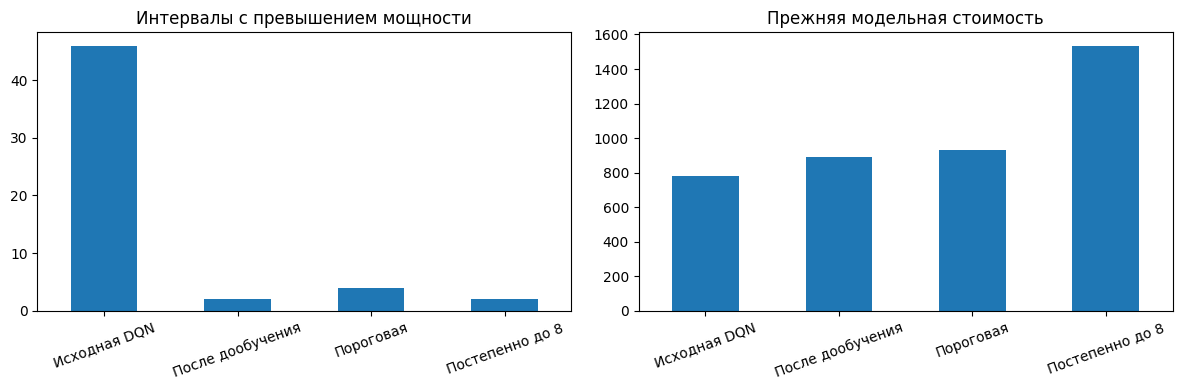

In [3]:
summary=pd.read_csv('results/safety/comparison.csv',index_col=0)
display(summary.round(3))
display(pd.read_csv('results/safety/test_seeds.csv'))
labels={'original_dqn':'Исходная DQN','safety_dqn':'После дообучения','threshold':'Пороговая','ramp_to_8':'Постепенно до 8'}
names=list(labels)
fig,axes=plt.subplots(1,2,figsize=(12,4))
summary.loc[names,'overloaded_slots'].rename(index=labels).plot.bar(ax=axes[0],rot=20,title='Интервалы с превышением мощности')
summary.loc[names,'cost'].rename(index=labels).plot.bar(ax=axes[1],rot=20,title='Прежняя модельная стоимость')
fig.tight_layout();fig.savefig('results/safety/comparison.png',dpi=150);plt.show()

Меньше перегрузки может означать больше серверов и более высокую стоимость. Сравниваем с простыми стратегиями. Нулевой результат на этом периоде не даёт гарантии для будущего. Перезапуск оценки не должен менять выбранный seed; для новой настройки используйте новый независимый период.